Predecir si un jugador de Primera o Segunda FEB se asentará en la ACB (al menos
15 partidos con 15 minutos por partido) en alguna de las 3 temporadas siguientes.

In [1]:
import sys
import warnings
from pathlib import Path


RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.datos import cargar_datos
from src.modelo import (NOMBRES, RUTA_PREDICCIONES, VARIABLES, contribuciones, evaluar,
                        explicar, guardar_modelo, preparar_variables, separar)

pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (8, 4)
SEMILLA = 42

## 1. Datos y particion por temp.

In [2]:
tabla = cargar_datos("dataset_modelo")
etiquetadas, candidatas = separar(tabla)
print(f"Filas con objetivo: {len(etiquetadas)} · positivos: {etiquetadas['se_asienta'].sum()} "
      f"({etiquetadas['se_asienta'].mean():.1%})")
print(f"Candidatas actuales (sin objetivo): {len(candidatas)}")
etiquetadas.groupby("temporada")["se_asienta"].agg(filas="size", positivos="sum").T

Filas con objetivo: 6116 · positivos: 305 (5.0%)
Candidatas actuales (sin objetivo): 1336


temporada,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
filas,307,338,337,305,370,300,283,235,258,270,276,316,318,431,412,465,445,450
positivos,17,25,27,25,27,22,24,13,10,10,12,10,13,12,13,16,13,16


Partición temporal: se entrena con el pasado y se evalúa con temporadas
posteriores, igual que se usará la herramienta. 
- **Entrenamiento:** 2005-2016
- **Validación**: 2017-2018
- **Prueba**: 2019-2022

In [3]:
particion = pd.cut(etiquetadas["temporada"], [0, 2016, 2018, 2022],
                   labels=["entrenamiento", "validacion", "prueba"])
entrenamiento = etiquetadas[particion == "entrenamiento"]
validacion = etiquetadas[particion == "validacion"]
prueba = etiquetadas[particion == "prueba"]

X_ent, y_ent = preparar_variables(entrenamiento), entrenamiento["se_asienta"]
X_val, y_val = preparar_variables(validacion), validacion["se_asienta"]
X_pru, y_pru = preparar_variables(prueba), prueba["se_asienta"]

pd.DataFrame({p: [len(d), int(d["se_asienta"].sum()), round(d["se_asienta"].mean(), 3)]
              for p, d in [("entrenamiento", entrenamiento), ("validacion", validacion), ("prueba", prueba)]},
             index=["filas", "positivos", "tasa"])

,entrenamiento,validacion,prueba
filas,3595.000,749.000,1772.000
positivos,222.000,25.000,58.000
tasa,0.062,0.033,0.033


In [4]:
print(f"{len(VARIABLES)} variables")
X_ent.isna().mean().sort_values(ascending=False).head(8).round(3)

35 variables


minutos_partido_cambio    0.489
asistencias_40_cambio     0.489
rebotes_40_cambio         0.489
puntos_40_cambio          0.489
valoracion_40_cambio      0.489
altura_cm                 0.216
t3_pct                    0.079
faltas_recibidas_40       0.021
dtype: float64

* Se entrena con 2005-2016, se elige el modelo con 2017-2018 y se evalúa con 2019-2022. La tasa de positivos baja del 6,2 % al 3,3 % entre el entrenamiento y los años recientes, así que las probabilidades del modelo pueden salir algo altas. Con solo 25 positivos en validación, las diferencias pequeñas entre modelos no son fiables.
* Los huecos (evolución, altura, % de triples) se rellenan con la mediana del entrenamiento.

## 2. Linea Base 

- **PR-AUC**: resume precisión y recall con clases desbalanceadas. Al azar valdría la tasa de positivos (~5 %).
- **ROC-AUC**: probabilidad de que un positivo quede por delante de un negativo.
- **recall@20 / precision@20**: en cada temporada se mira la lista de los 20 primeros; qué parte de los que se asentaron estaba en la lista y qué parte de la lista se asentó.

In [5]:
lineas_base = {
    "minutos": "minutos",
    "valoración por 40": "valoracion_40",
}
filas = {nombre: evaluar(validacion, validacion[col].fillna(0)) for nombre, col in lineas_base.items()}
pd.DataFrame(filas).T.round(3)

,PR-AUC,ROC-AUC,recall@20,precision@20
minutos,0.058,0.692,0.04,0.025
valoración por 40,0.220,0.738,0.28,0.175


* Sin modelo, ordenar por valoración por 40 da un PR-AUC de 0,22 en validación, y ordenar por minutos solo 0,058 (al azar sería 0,033). El modelo tiene que superar las cifras para aportar algo.

## 3. Modelos

- **Regresión logística**
- **Random forest**
- **LightGBM**
- **Red neuronal (MLP)** 

In [6]:
def modelos_base():
    return {
        "Regresión logística": make_pipeline(
            SimpleImputer(strategy="median"), StandardScaler(),
            LogisticRegression(C=0.3, max_iter=3000)),
        "Random forest": make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestClassifier(n_estimators=500, min_samples_leaf=5, n_jobs=-1,
                                   random_state=SEMILLA)),
        "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15,
                                   min_child_samples=20, subsample=0.8, subsample_freq=1,
                                   colsample_bytree=0.8, random_state=SEMILLA, verbose=-1),
        "Red neuronal (MLP)": make_pipeline(
            SimpleImputer(strategy="median"), StandardScaler(),
            MLPClassifier(hidden_layer_sizes=(16,), alpha=1.0, max_iter=2000,
                          random_state=SEMILLA)),
    }

resultados = {}
for nombre, modelo in modelos_base().items():
    modelo.fit(X_ent, y_ent)
    resultados[nombre] = evaluar(validacion, modelo.predict_proba(X_val)[:, 1])
for nombre, col in lineas_base.items():
    resultados[f"Línea base: {nombre}"] = evaluar(validacion, validacion[col].fillna(0))
tabla_validacion = pd.DataFrame(resultados).T.sort_values("PR-AUC", ascending=False)
tabla_validacion.round(3)

,PR-AUC,ROC-AUC,recall@20,precision@20
Red neuronal (MLP),0.335,0.849,0.52,0.325
Regresión logística,0.299,0.847,0.52,0.325
Línea base: valoración por 40,0.220,0.738,0.28,0.175
LightGBM,0.210,0.833,0.40,0.250
Random forest,0.189,0.815,0.40,0.250
Línea base: minutos,0.058,0.692,0.04,0.025


* La red neuronal (PR-AUC 0,335) y la regresión logística (0,299) son los mejores modelos y superan a la mejor línea base (0,22). Con ellos, la mitad de los jugadores que se asentaron estaban entre los 20 primeros de su temporada, frente al 28 % sin modelo.
* LightGBM y random forest sin ajustar quedan por debajo de la línea base: con tan pocos positivos, los modelos no ganan.

## 4. Optuna

In [7]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objetivo(trial):
    modelo = LGBMClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 800),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        num_leaves=trial.suggest_int("num_leaves", 4, 31),
        min_child_samples=trial.suggest_int("min_child_samples", 10, 80),
        subsample=trial.suggest_float("subsample", 0.6, 1.0), subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        random_state=SEMILLA, verbose=-1)
    modelo.fit(X_ent, y_ent)
    return evaluar(validacion, modelo.predict_proba(X_val)[:, 1])["PR-AUC"]

estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEMILLA))
estudio.optimize(objetivo, n_trials=40)
print(f"PR-AUC en validación: {estudio.best_value:.3f} (sin ajustar: "
      f"{tabla_validacion.loc['LightGBM', 'PR-AUC']:.3f})")
estudio.best_params

PR-AUC en validación: 0.279 (sin ajustar: 0.210)


{'n_estimators': 535,
 'learning_rate': 0.016201703212321852,
 'num_leaves': 11,
 'min_child_samples': 64,
 'subsample': 0.746909454881543,
 'colsample_bytree': 0.446783580297849,
 'reg_lambda': 0.904351222374337}

In [8]:
candidatos = modelos_base()
candidatos["LightGBM ajustado"] = LGBMClassifier(**estudio.best_params, subsample_freq=1,
                                                 random_state=SEMILLA, verbose=-1)
for nombre in ["LightGBM ajustado"]:
    candidatos[nombre].fit(X_ent, y_ent)
    tabla_validacion.loc[nombre] = evaluar(validacion, candidatos[nombre].predict_proba(X_val)[:, 1])

EXPLICABLES = ["Regresión logística", "Random forest", "LightGBM", "LightGBM ajustado"]
elegido = tabla_validacion.loc[EXPLICABLES, "PR-AUC"].idxmax()
print("Modelo elegido (mejor PR-AUC en validación entre los explicables):", elegido)
tabla_validacion.sort_values("PR-AUC", ascending=False).round(3)

Modelo elegido (mejor PR-AUC en validación entre los explicables): Regresión logística


,PR-AUC,ROC-AUC,recall@20,precision@20
Red neuronal (MLP),0.335,0.849,0.52,0.325
Regresión logística,0.299,0.847,0.52,0.325
LightGBM ajustado,0.279,0.830,0.40,0.250
Línea base: valoración por 40,0.220,0.738,0.28,0.175
LightGBM,0.210,0.833,0.40,0.250
Random forest,0.189,0.815,0.40,0.250
Línea base: minutos,0.058,0.692,0.04,0.025


* Optuna mejora LightGBM de 0,21 a 0,279 de PR-AUC, pero sigue por debajo de la regresión logística (0,299). Como los parámetros se eligen mirando la validación.
* Se elige la regresión logística ya que es la mejor de los modelos explicables.

## 5. Evaluacion final 

In [9]:
from sklearn.base import clone

hasta_2018 = pd.concat([entrenamiento, validacion])
X_hasta_2018, y_hasta_2018 = preparar_variables(hasta_2018), hasta_2018["se_asienta"]

finales = {nombre: clone(modelo) for nombre, modelo in candidatos.items()}
puntuacion_prueba = {}
for nombre, modelo in finales.items():
    modelo.fit(X_hasta_2018, y_hasta_2018)
    puntuacion_prueba[nombre] = modelo.predict_proba(X_pru)[:, 1]
for nombre, col in lineas_base.items():
    puntuacion_prueba[f"Línea base: {nombre}"] = prueba[col].fillna(0).values

tabla_prueba = pd.DataFrame({n: evaluar(prueba, p) for n, p in puntuacion_prueba.items()}).T
tabla_prueba.round(3)

,PR-AUC,ROC-AUC,recall@20,precision@20
Regresión logística,0.212,0.857,0.310,0.225
Random forest,0.207,0.836,0.310,0.225
LightGBM,0.254,0.875,0.328,0.238
Red neuronal (MLP),0.204,0.864,0.276,0.200
LightGBM ajustado,0.249,0.875,0.328,0.238
Línea base: minutos,0.117,0.716,0.241,0.175
Línea base: valoración por 40,0.082,0.696,0.121,0.088


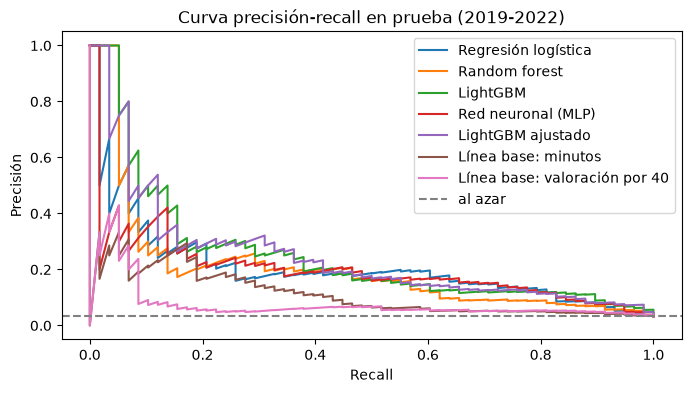

In [10]:
fig, ax = plt.subplots()
for nombre, p in puntuacion_prueba.items():
    precision, recall, _ = precision_recall_curve(y_pru, p)
    ax.plot(recall, precision, label=nombre)
ax.axhline(y_pru.mean(), color="grey", linestyle="--", label="al azar")
ax.set(title="Curva precisión-recall en prueba (2019-2022)", xlabel="Recall", ylabel="Precisión")
ax.legend()
plt.show()

* En prueba (2019-2022), la regresión logística da un PR-AUC de 0,212, mucho más que el azar (0,033) y casi el doble que ordenar por minutos (0,117).
* LightGBM sale algo mejor en prueba (0,25), pero no se cambia de modelo. las diferencias entre los modelos son pequeñas y no son estables de un periodo a otro.

#### Jugadores con pasaporte español

In [11]:
modelo_elegido = finales[elegido]
p_elegido = puntuacion_prueba[elegido]
filas = {}
for etiqueta, mascara in [("pasaporte español", prueba["es_nacional_feb"] == 1),
                          ("otro pasaporte", prueba["es_nacional_feb"] != 1)]:
    sub = prueba[mascara.values]
    filas[(etiqueta, elegido)] = {"filas": len(sub), "positivos": int(sub["se_asienta"].sum()),
                                  **evaluar(sub, p_elegido[mascara.values], k=10)}
    filas[(etiqueta, "Línea base: minutos")] = {"filas": len(sub), "positivos": int(sub["se_asienta"].sum()),
                                                **evaluar(sub, sub["minutos"].fillna(0), k=10)}
pd.DataFrame(filas).T.round(3)

filas  positivos  PR-AUC  ROC-AUC  \
pasaporte español Regresión logística  967.0       25.0   0.214    0.861   
                  Línea base: minutos  967.0       25.0   0.088    0.657   
otro pasaporte    Regresión logística  805.0       33.0   0.245    0.846   
                  Línea base: minutos  805.0       33.0   0.174    0.756   

                                       recall@10  precision@10  
pasaporte español Regresión logística      0.360         0.225  
                  Línea base: minutos      0.200         0.125  
otro pasaporte    Regresión logística      0.182         0.150  
                  Línea base: minutos      0.273         0.225

* Con los jugadores de pasaporte español, el modelo es 2,4 veces mejor que ordenar por minutos (PR-AUC 0,214 frente a 0,088) y en el top 10 de cada temporada encuentra al 36 % de los que se asentaron, frente al 20 %. Es justo el grupo que interesa al caso de uso.

## 6. Que ha aprendido SHAP?

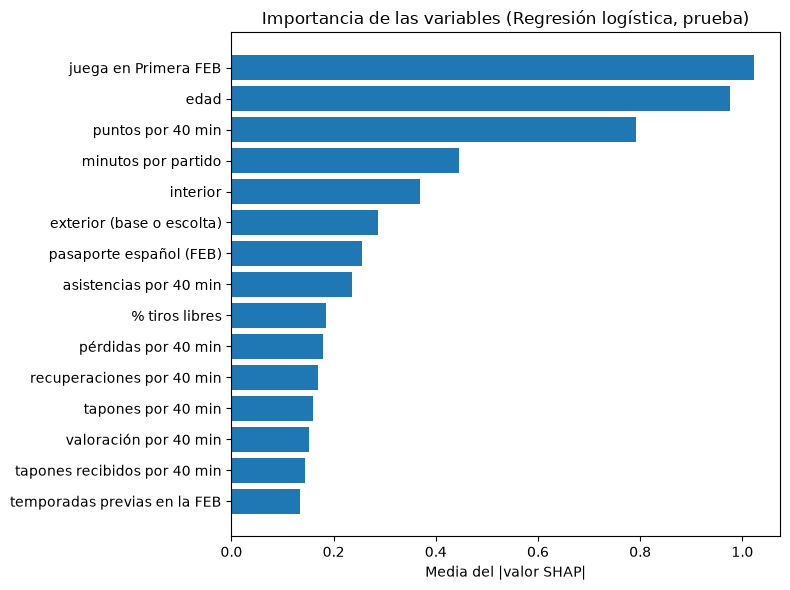

In [12]:
contrib_prueba = contribuciones(modelo_elegido, X_pru)
importancia = contrib_prueba.abs().mean().sort_values().tail(15)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([NOMBRES.get(v, v) for v in importancia.index], importancia.values)
ax.set(title=f"Importancia de las variables ({elegido}, prueba)",
       xlabel="Media del |valor SHAP|")
plt.tight_layout()
plt.show()

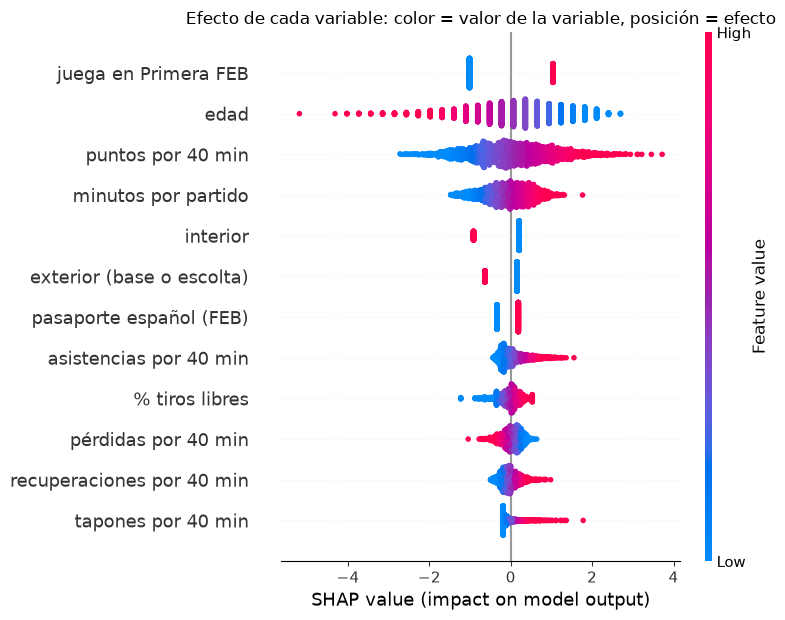

In [13]:
import shap
shap.summary_plot(contrib_prueba.values, X_pru.rename(columns=NOMBRES), max_display=12, show=False)
plt.title("Efecto de cada variable: color = valor de la variable, posición = efecto")
plt.tight_layout()
plt.show()

* Lo que más pesa en el modelo es jugar en Primera FEB, la edad (los más jóvenes suben), los puntos por 40 y los minutos por partido. Lo mismo que vimos en el EDA.
* Los aleros salen favorecidos frente a interiores y exteriores, y tener pasaporte español suma un poco. Más asistencias, robos y tapones suman; más pérdidas restan.

#### Prueba de porqué el modelo destaca a un jugador para bien o mal

In [14]:
ordenados = prueba.assign(p=p_elegido).sort_values("p", ascending=False)
ejemplos = {"Primero del ranking en prueba": ordenados.iloc[0],
            "Primer fallo del ranking (no se asentó)": ordenados[ordenados["se_asienta"] == 0].iloc[0]}
for titulo, ejemplo in ejemplos.items():
    a_favor, en_contra = explicar(contrib_prueba.loc[ejemplo.name], X_pru.loc[ejemplo.name])
    print(f"{titulo}: {ejemplo['jugador']} ({ejemplo['competicion']}, {ejemplo['temporada']}) · "
          f"probabilidad {ejemplo['p']:.0%} · se asentó?: {'sí' if ejemplo['se_asienta'] else 'no'}")
    print("   A favor:", ", ".join(a_favor))
    print("   En contra:", ", ".join(en_contra) or "nada destacable")

Primero del ranking en prueba: MONTERO BERROA, JEAN CLAUDIO (segunda_feb, 2020) · probabilidad 88% · se asentó?: sí
   A favor: puntos por 40 min (24.9), edad (17), minutos por partido (30.1)
   En contra: no: juega en Primera FEB, pérdidas por 40 min (4.3), no: pasaporte español (FEB)
Primer fallo del ranking (no se asentó): JIMENEZ GARRIDO, MILLAN (segunda_feb, 2021) · probabilidad 75% · se asentó?: no
   A favor: puntos por 40 min (25.5), edad (19), minutos por partido (29.4)
   En contra: no: juega en Primera FEB, tapones recibidos por 40 min (1.0), partidos jugados (14)


## 7. Modelo final + predicciones para la app

In [15]:
modelo_final = clone(candidatos[elegido])
X_todo = preparar_variables(etiquetadas)
modelo_final.fit(X_todo, etiquetadas["se_asienta"])
guardar_modelo(modelo_final, elegido, {"validacion": tabla_validacion.loc[elegido].to_dict(),
                                       "prueba": tabla_prueba.loc[elegido].to_dict()})

X_cand = preparar_variables(candidatas)
candidatas = candidatas.assign(probabilidad=modelo_final.predict_proba(X_cand)[:, 1])
contrib_cand = contribuciones(modelo_final, X_cand)
motivos = [explicar(contrib_cand.loc[i], X_cand.loc[i]) for i in candidatas.index]
candidatas["a_favor"] = [", ".join(a) for a, _ in motivos]
candidatas["en_contra"] = [", ".join(e) for _, e in motivos]
candidatas["puesto_ranking"] = (candidatas.groupby("temporada")["probabilidad"]
                                .rank(ascending=False, method="first").astype(int))

columnas = ["id_feb", "jugador", "equipo", "competicion", "temporada", "edad", "puesto",
            "altura_cm", "es_nacional_feb", "partidos", "minutos_partido", "puntos_40",
            "rebotes_40", "asistencias_40", "valoracion_40", "probabilidad", "puesto_ranking",
            "a_favor", "en_contra"]
candidatas[columnas].sort_values(["temporada", "puesto_ranking"]).to_csv(RUTA_PREDICCIONES, index=False)
print(f"Modelo guardado ({elegido}); {len(candidatas)} predicciones en {RUTA_PREDICCIONES.name}")
candidatas[candidatas["temporada"] == candidatas["temporada"].max()].nsmallest(10, "puesto_ranking")[
    ["jugador", "competicion", "edad", "es_nacional_feb", "minutos_partido", "probabilidad", "a_favor"]]

Modelo guardado (Regresión logística); 1336 predicciones en predicciones.csv


,jugador,competicion,edad,es_nacional_feb,minutos_partido,probabilidad,a_favor
6021,"DIAZ, MATEO",primera_feb,23.0,0,27.617188,0.409843,"juega en Primera FEB, puntos por 40 min (19.6)..."
2637,"PERIS CRESPO, JOSEP",primera_feb,25.0,1,19.486458,0.337484,"puntos por 40 min (25.7), juega en Primera FEB..."
4057,"ANSORREGUI DEBA, MANEX",primera_feb,23.0,1,22.793229,0.323172,"juega en Primera FEB, edad (23), valoración po..."
2940,"VAZQUEZ PEREZ, ISAAC",primera_feb,21.0,1,19.481771,0.295188,"edad (21), juega en Primera FEB, asistencias p..."
5785,"BARCELLO, ALEXANDER MICHAEL",primera_feb,27.0,0,22.334375,0.275094,"puntos por 40 min (23.4), juega en Primera FEB..."
3388,"MARTINEZ CLARIANA, ALVARO",primera_feb,22.0,1,21.286979,0.268046,"juega en Primera FEB, edad (22), valoración po..."
6167,"ROBERTS, TYRELL PAUL",primera_feb,26.0,0,22.440580,0.256882,"puntos por 40 min (28.8), juega en Primera FEB..."
5856,"LITTLESON, SPENCER PHILLIP",primera_feb,27.0,0,27.950000,0.224766,"puntos por 40 min (23.9), juega en Primera FEB..."
5914,"HANZLIK, ONDREJ",primera_feb,23.0,0,20.651563,0.200750,"juega en Primera FEB, edad (23), % tiros de 2 ..."
5819,"DE SOUZA PACHECO, CAIO",primera_feb,26.0,0,21.563889,0.198781,"juega en Primera FEB, puntos por 40 min (21.3)..."


* El modelo final se entrena con todas las temporadas 2005-2022 y se aplica a los 1.336 candidatos de 2023-2025, que son los que muestra la aplicación. En 2025, los 10 primeros juegan en Primera FEB y 4 tienen pasaporte español.
* La probabilidad más alta es del 41 %: sirve para ordenar a los candidatos. Puede estar algo inflada porque el modelo aprendió de años con más positivos.